# Subgraph as node action sample

In [1]:
var userHomeDir = System.getProperty("user.home");
var localRespoUrl = "file://" + userHomeDir + "/.m2/repository/";
var langchain4jVersion = "1.22.0";
var langchain4jbeta = "1.22.0-beta32";
var langgraph4jVersion = "1.9.10";

In [2]:
%%bash 
rm -rf \{userHomeDir}/Library/Jupyter/kernels/rapaio-jupyter-kernel/mima_cache/org/bsc/langgraph4j

In [3]:
%dependency /add-repo local \{localRespoUrl} release|never snapshot|always
// %dependency /list-repos
%dependency /add org.slf4j:slf4j-jdk14:2.0.9
%dependency /add org.bsc.langgraph4j:langgraph4j-core:\{langgraph4jVersion}
%dependency /add org.bsc.langgraph4j:langgraph4j-langchain4j:\{langgraph4jVersion}
%dependency /add dev.langchain4j:langchain4j:\{langchain4jVersion}
%dependency /add dev.langchain4j:langchain4j-open-ai:\{langchain4jVersion}
%dependency /add net.sourceforge.plantuml:plantuml-mit:1.2024.8

%dependency /resolve

Repository local url: file:///Users/bsorrentino/.m2/repository/ added.
Adding dependency org.slf4j:slf4j-jdk14:2.0.9
Adding dependency org.bsc.langgraph4j:langgraph4j-core:1.9.10
Adding dependency org.bsc.langgraph4j:langgraph4j-langchain4j:1.9.10
Adding dependency dev.langchain4j:langchain4j:1.22.0
Adding dependency dev.langchain4j:langchain4j-open-ai:1.22.0
Adding dependency net.sourceforge.plantuml:plantuml-mit:1.2024.8
Solving dependencies
Resolved artifacts count: 22
Add to classpath: /Users/bsorrentino/Library/Jupyter/kernels/rapaio-jupyter-kernel/mima_cache/org/slf4j/slf4j-jdk14/2.0.9/slf4j-jdk14-2.0.9.jar
Add to classpath: /Users/bsorrentino/Library/Jupyter/kernels/rapaio-jupyter-kernel/mima_cache/org/slf4j/slf4j-api/2.0.9/slf4j-api-2.0.9.jar
Add to classpath: /Users/bsorrentino/Library/Jupyter/kernels/rapaio-jupyter-kernel/mima_cache/org/bsc/langgraph4j/langgraph4j-core/1.9.10/langgraph4j-core-1.9.10.jar
Add to classpath: /Users/bsorrentino/Library/Jupyter/kernels/rapaio-jupyt

**utility to render graph respresentation in PlantUML**

In [4]:
import net.sourceforge.plantuml.SourceStringReader;
import net.sourceforge.plantuml.FileFormatOption;
import net.sourceforge.plantuml.FileFormat;
import org.bsc.langgraph4j.GraphRepresentation;

void displayDiagram( GraphRepresentation representation ) throws IOException { 
    
    var reader = new SourceStringReader(representation.getContent());

    try(var imageOutStream = new java.io.ByteArrayOutputStream()) {

        var description = reader.outputImage( imageOutStream, 0, new FileFormatOption(FileFormat.PNG));

        var imageInStream = new java.io.ByteArrayInputStream(  imageOutStream.toByteArray() );

        var image = javax.imageio.ImageIO.read( imageInStream );

        display(  image );

    }
}

**Graph State**

In [5]:
import org.bsc.langgraph4j.prebuilt.MessagesState;
import org.bsc.langgraph4j.state.Channel;

public class State extends MessagesState<String> {

    public State(Map<String, Object> initData) {
        super( initData  );
    }
}

**Create Action Catalog**

In [6]:
import org.bsc.langgraph4j.annotation.ActionCatalogRepository;
import org.bsc.langgraph4j.annotation.ActionCatalog;
import org.bsc.langgraph4j.annotation.NodeAction;
import org.bsc.langgraph4j.annotation.EdgeCondition;
import org.bsc.langgraph4j.*;

final var repo = ActionCatalogRepository.of( new ActionCatalog() {

    @NodeAction
    public Map<String, Object> makeNode( State state, RunnableConfig config ) {
        return Map.of("messages", config.nodePath().toString() );
    }

    @EdgeCondition( name = "continue")
    public String continueNode( State state, RunnableConfig config ) {
        return "continue";
    }
});


In [7]:
import org.bsc.langgraph4j.StateGraph;
import org.bsc.langgraph4j.utils.EdgeMappings;
import org.bsc.langgraph4j.action.AsyncNodeAction;
import static org.bsc.langgraph4j.action.AsyncNodeAction.node_async;
import static org.bsc.langgraph4j.action.AsyncEdgeAction.edge_async;
import static org.bsc.langgraph4j.StateGraph.END;
import static org.bsc.langgraph4j.StateGraph.START;

var workflowChild = new StateGraph<>(State.SCHEMA, State::new)        
                    .add( repo.node("child:step_1", "makeNode") )
                    .add( repo.node("child:step_2", "makeNode") )
                    .add( repo.node("child:step_3", "makeNode") )
                    .addEdge(START, "child:step_1")
                    .addEdge("child:step_1", "child:step_2")
                    .add(  repo.edge("child:step_2", "continue", 
                                EdgeMappings.builder()
                                    .toEND()
                                    .to( "child:step_3", "continue")
                                    .build() ))
                    .addEdge("child:step_3", END)
                    ;
var compiledWorkflowChild = workflowChild.compile();

**Create graph with a sub graph as action node**
> The subgraph will be executed independently to the parent without share anything

In [ ]:

var workflow = new StateGraph<>(State.SCHEMA, State::new)        
                    .add( repo.node("step_1",  "makeNode") )
                    .add( repo.node("step_2",  "makeNode") )
                    .add( repo.node("step_3",  "makeNode") )
                    .addNode( "subgraph",  (state, config) -> {

                        final var input =  GraphInput.args(state.data());

                        return compiledWorkflowChild.stream( input, RunnableConfig.empty() )
                            .forEachAsync( System.out::println )
                            .thenApply( res -> state.data() );

                     })
                    .addEdge(START, "step_1")
                    .addEdge("step_1", "step_2")
                    .addEdge("step_2", "subgraph")
                    .addEdge("subgraph", "step_3")
                    .addEdge("step_3", END)
                    ;

var compiledWorkflow = workflow.compile();

for( var step : compiledWorkflow.stream( Map.of() )) {
    System.out.println( step );
}

NodeOutput{ node=__START__, state={
	messages=[]
}}
NodeOutput{ node=step_1, state={
	messages=[
	step_1
	]
}}
NodeOutput{ node=step_2, state={
	messages=[
	step_1
	step_2
	]
}}
NodeOutput{ node=__START__, state={
	messages=[
	step_1
	step_2
	]
}}
NodeOutput{ node=child:step_1, state={
	messages=[
	step_1
	step_2
	child:step_1
	]
}}
NodeOutput{ node=child:step_2, state={
	messages=[
	step_1
	step_2
	child:step_1
	child:step_2
	]
}}
NodeOutput{ node=child:step_3, state={
	messages=[
	step_1
	step_2
	child:step_1
	child:step_2
	child:step_3
	]
}}
NodeOutput{ node=__END__, state={
	messages=[
	step_1
	step_2
	child:step_1
	child:step_2
	child:step_3
	]
}}
NodeOutput{ node=subgraph, state={
	messages=[
	step_1
	step_2
	]
}}
NodeOutput{ node=step_3, state={
	messages=[
	step_1
	step_2
	step_3
	]
}}
NodeOutput{ node=__END__, state={
	messages=[
	step_1
	step_2
	step_3
	]
}}


**Display Graph** 

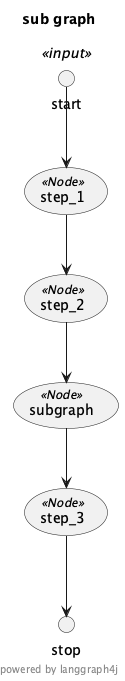

In [9]:
var representation = workflow.getGraph( GraphRepresentation.Type.PLANTUML, "sub graph", false );

displayDiagram( representation );